In [34]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import baltic as bt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import io, re, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from matplotlib.collections import LineCollection
from matplotlib.patches import ConnectionPatch
from matplotlib.lines import Line2D
from Bio import Phylo

from scipy.stats import spearmanr, pearsonr, rankdata

In [24]:
PATRISTIC_FILE = "../output/patristic_MCC_DENV{sero}.csv"
PROYECTION_COORDS = "../output/projected_coordinates_DENV{}.csv"
META_CLEAN_COL = "merged_metadata/meta_merged_{}.tsv"

TREE_FILES = {
    1: "../resources/BEAST/DENV1_BDSKY_MCC.tree",
    2: "../resources/BEAST/DENV2_BDSKY_MCC.tree",
    3: "../resources/BEAST/DENV3_BDSKY_MCC.tree",
    4: "../resources/BEAST/DENV4_BDSKY_MCC.tree",
}

DATES_FILES = {s: f"../resources/colombia_data/dates/DENV{s}_dates_beauti.txt" for s in (1, 2, 3, 4)}
OUTPUT_FILE = "../figures/DENV_beast_trees.jpeg"

SERO_COLORS = {1: "#D55E00", 2: "#009E73", 3: "#56B4E9", 4: "#CC79A7"}
TREESTRING_RX = r'tree [A-Za-z\_0-9]+'

plt.rcParams['font.family'] = 'sans-serif'

# Transmission Dynamics

In [25]:
def load_beast_tree(tree_path, dates_path):
    """Carga un MCC de BEAST/TreeAnnotator y le fija el tiempo absoluto.

    Las puntas solo llevan el año, y baltic descarta las fechas con
    incertidumbre, así que el tiempo absoluto se toma de las fechas de BEAUti.
    """
    ll = bt.load_nexus(tree_path, treeType="time", absoluteTime=False,
                       treestringRegex=TREESTRING_RX)
    fechas = {}
    with open(dates_path) as f:
        for line in f:
            if line.strip():
                nombre, fecha = line.rstrip("\n").split("\t")
                fechas[nombre] = float(fecha)
    ll.set_absolute_time(max(fechas.values()))
    return ll

## Figura: Arboles MCC

DENV-1: 308 puntas | raíz 1998.3
DENV-2: 475 puntas | raíz 1998.5
DENV-3: 264 puntas | raíz 1999.6
DENV-4: 48 puntas | raíz 1997.9


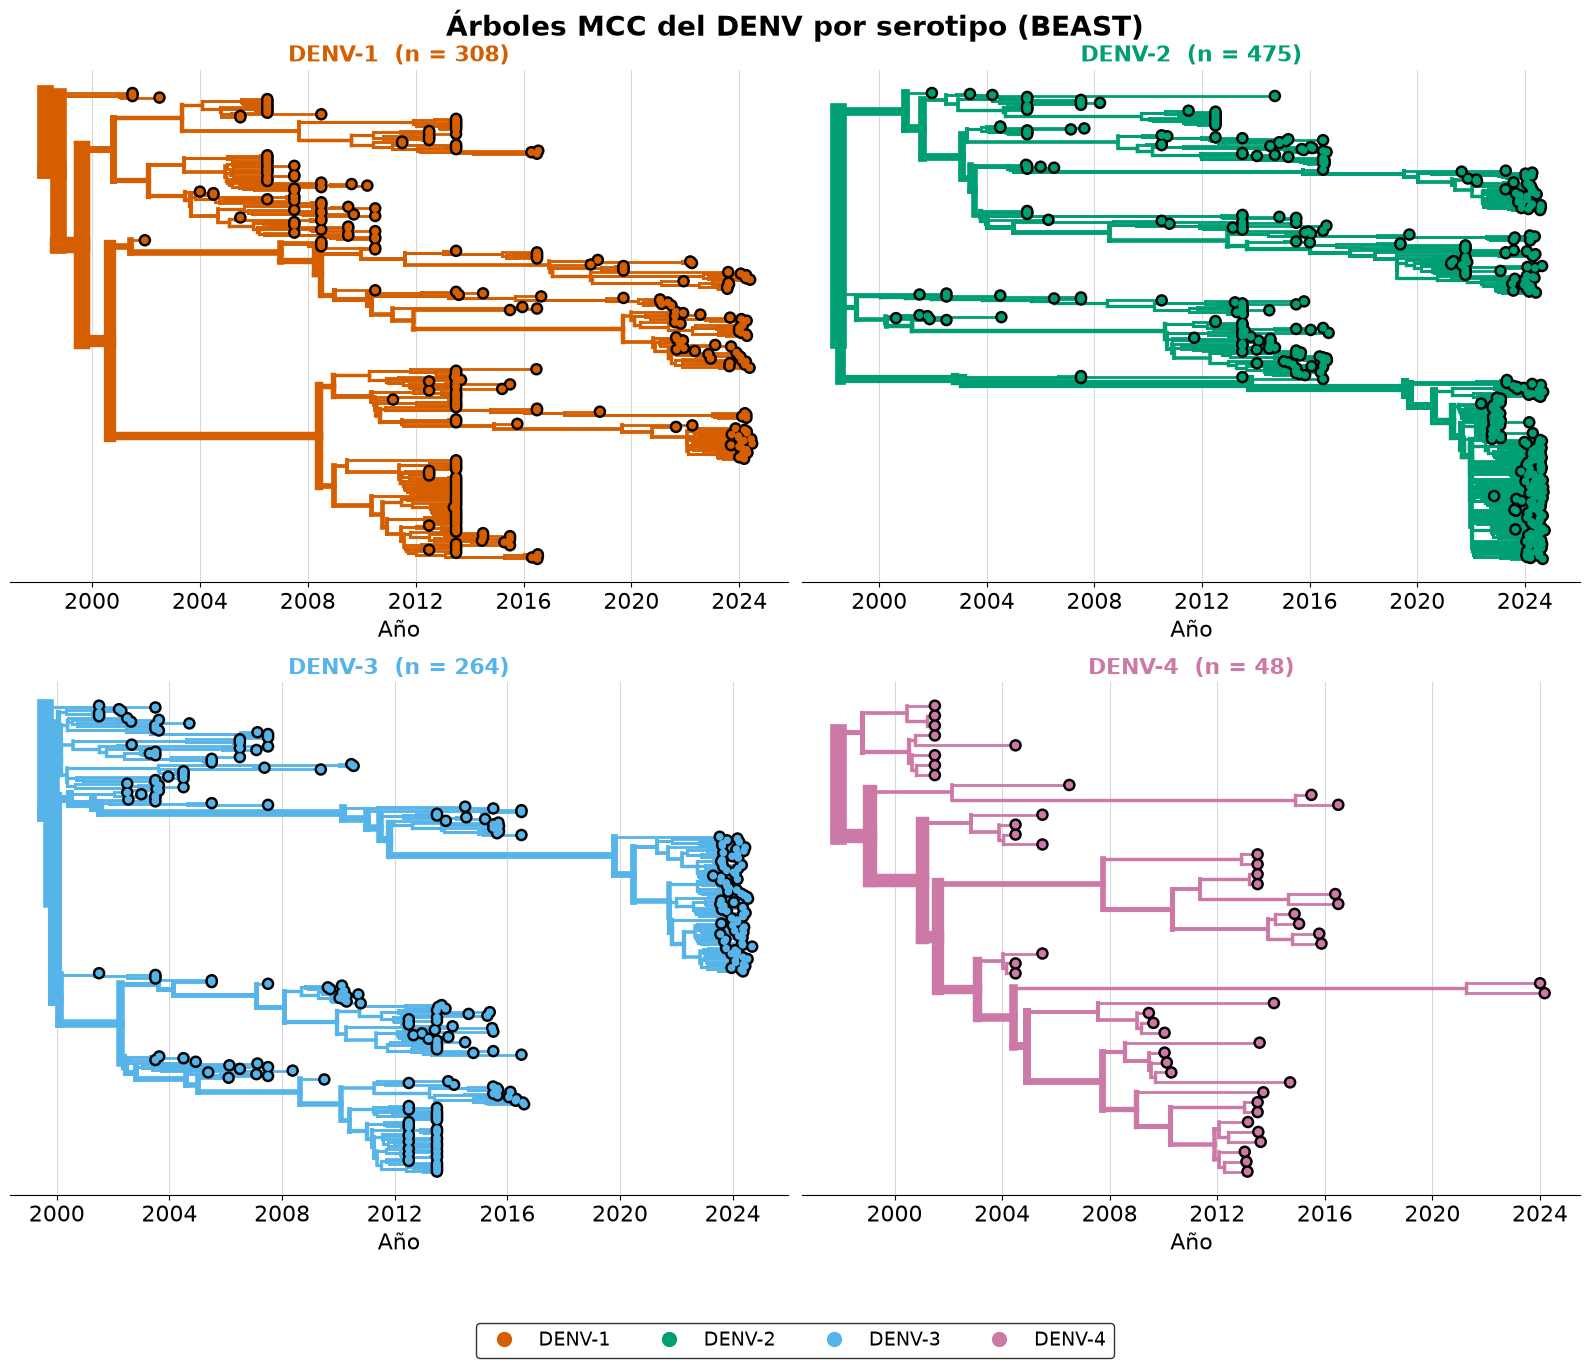


Figura guardada en: ../figures/DENV_beast_trees.jpeg


In [26]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, sero in enumerate([1, 2, 3, 4]):
    ax = axes[idx]
    color = SERO_COLORS[sero]

    ll = load_beast_tree(TREE_FILES[sero], DATES_FILES[sero])

    # Función de color: todo del mismo color
    def c_func(k, color=color):
        return color

    # Grosor de ramas proporcional al número de hojas descendientes
    L = sum(1 for k in ll.Objects if k.branchType == "leaf")
    b_func = lambda k: (
        2 + 10.0 * len(k.leaves) / L
        if k.branchType == "node"
        else 2
    )

    # Graficar árbol (esta versión de baltic usa snake_case y sufijo Fxn)
    x_abs = lambda k: k.absoluteTime
    ll.plot_tree(ax, xCoordinateFxn=x_abs, widthFxn=b_func,
                 colourFxn=c_func, zorder=20000)
    ll.plot_points(ax, xCoordinateFxn=x_abs, pointSize=30,
                   colourFxn=c_func, zorder=20002)

    # Estética
    for loc in ["left", "right", "top"]:
        ax.spines[loc].set_visible(False)

    ax.grid(axis="x", ls="-", color="grey", alpha=0.3)
    ax.tick_params(axis="y", size=0)
    ax.tick_params(axis="x", labelsize=16)
    ax.set_xlabel("Año", fontsize=16)
    ax.set_yticklabels([])
    ax.set_title(f"DENV-{sero}  (n = {L})", fontsize=16, fontweight="bold",
                 color=color)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True, nbins=8))

    print(f"DENV-{sero}: {L} puntas | raíz {min(k.absoluteTime for k in ll.Objects):.1f}")

# ============================================================
# TÍTULO Y LEYENDA
# ============================================================
fig.suptitle(
    "Árboles MCC del DENV por serotipo (BEAST)",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=f"DENV-{sero}",
        markerfacecolor=SERO_COLORS[sero],
        markersize=12
    )
    for sero in [1, 2, 3, 4]
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    fontsize=14,
    frameon=True,
    edgecolor="black",
    ncol=4
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"\nFigura guardada en: {OUTPUT_FILE}")


## Relacion arbol MCC - Mapap antignico

orden de los paneles: [2, 3, 4, 1]
DENV2: 475 hojas | 467 con coordenadas | 9 linajes, 3 con tono propio, 8 en Otros
DENV3: 264 hojas | 261 con coordenadas | 2 linajes, 2 con tono propio, 0 en Otros
DENV4: 48 hojas | 48 con coordenadas | 5 linajes, 3 con tono propio, 4 en Otros
DENV1: 308 hojas | 304 con coordenadas | 10 linajes, 3 con tono propio, 102 en Otros


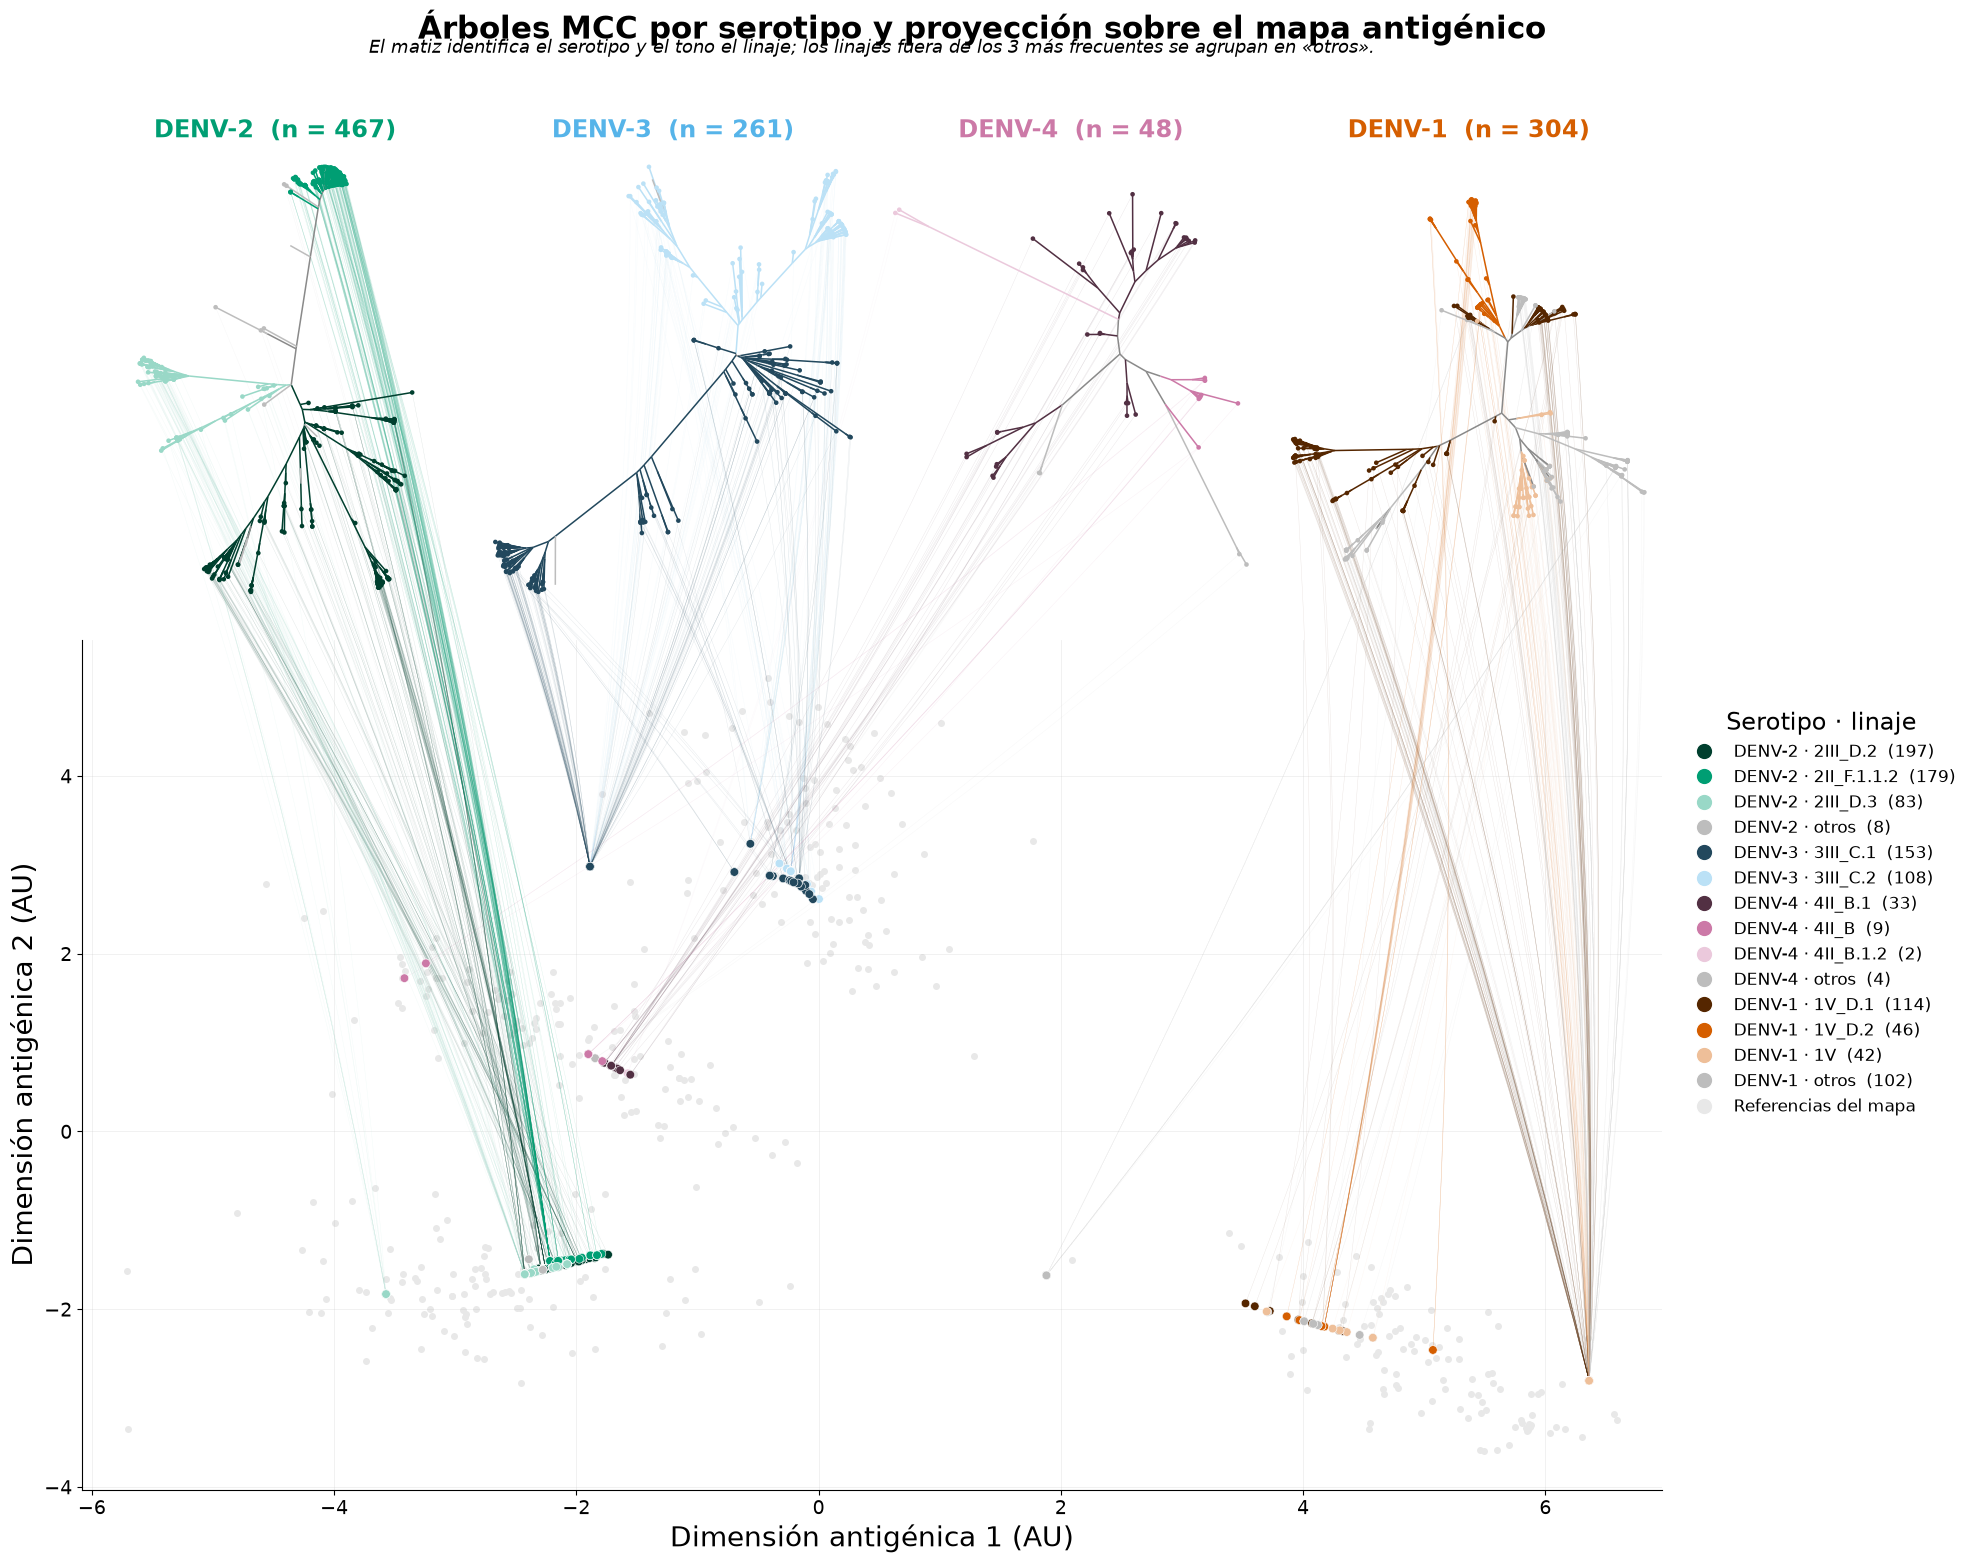

In [21]:
sys.setrecursionlimit(10000)

MAPA_AG_FILE = "../resources/experimental_data/2d-antigenic-map.txt"
META_CLEAN_COL = "merged_metadata/meta_merged_{}.tsv"

# Paleta Okabe-Ito: pasa validación de daltonismo (deutan/protan/tritan).
SERO_COLORS = {1: "#D55E00", 2: "#009E73", 3: "#56B4E9", 4: "#CC79A7"}
GRIS_OTROS = "#BDBDBD"

# Dentro de un mismo matiz solo se distinguen unos pocos niveles. Con tres tonos
# el peor par queda en ΔE 16.9 (piso 15); con cuatro cae a 10-13 y deja de leerse.
MAX_LINAJES = 3


def lineage_shades(base_hex, n, claro=0.6, oscuro=0.6):
    """n tonos del color del serotipo, de oscuro a claro. El tono central es el
    color base, así cada grupo sigue leyéndose como su serotipo."""
    base = np.array(mcolors.to_rgb(base_hex))
    if n == 1:
        return [mcolors.to_hex(base)]
    out = []
    for t in np.linspace(-claro, oscuro, n):
        c = base + (1 - base) * (-t) if t < 0 else base * (1 - t)
        out.append(mcolors.to_hex(np.clip(c, 0, 1)))
    return out[::-1]        # el más abundante primero, y es el más oscuro


def lineage_series(meta_template, sero):
    meta = pd.read_csv(meta_template.format(sero), sep="\t")
    key = "strain" if "strain" in meta.columns else meta.columns[0]
    return meta.drop_duplicates(key).set_index(key)["lineage"]


def unrooted_layout(ll, rotate=0.2):
    """Coloca cada nodo del árbol de baltic en el plano (equal-angle).
    Devuelve edges: [(padre, hijo, (x0,y0), (x1,y1))] y pos: id(nodo) -> (x,y)."""
    n_leaves = {}

    def count(k):
        n_leaves[id(k)] = 1 if k.branchType == "leaf" else sum(count(c) for c in k.children)
        return n_leaves[id(k)]
    count(ll.root)

    pos, edges = {}, []

    def rec(k, x, y, a0, a1):
        pos[id(k)] = (x, y)
        if k.branchType == "leaf":
            return
        ang = a0
        for ch in sorted(k.children, key=lambda c: -n_leaves[id(c)]):
            span = (a1 - a0) * n_leaves[id(ch)] / n_leaves[id(k)]
            mid = ang + span / 2
            L = ch.length or 0.0
            cx, cy = x + L * np.cos(mid), y + L * np.sin(mid)
            edges.append((k, ch, (x, y), (cx, cy)))
            rec(ch, cx, cy, ang, ang + span)
            ang += span
    rec(ll.root, 0.0, 0.0, rotate, rotate + 2 * np.pi)
    return edges, pos


def plot_trees_one_map(projected_coordinates, ref_xy=None, connect=True,
                       rotate=0.2, out=None, max_lineas_por_sero=None,
                       max_linajes=MAX_LINAJES):
    """Los cuatro árboles MCC en fila, con las aristas apuntando a un único mapa.
    El matiz identifica el serotipo y el tono el linaje dentro de ese serotipo."""
    fig = plt.figure(figsize=(20, 16), facecolor="w")
    gs = gridspec.GridSpec(2, 4, height_ratios=[0.55, 1], hspace=0.04, wspace=0.03,
                           left=0.05, right=0.84, top=0.90, bottom=0.06)
    ax_map = fig.add_subplot(gs[1, :])
    ax_trees = [fig.add_subplot(gs[0, i]) for i in range(4)]

    if ref_xy is not None:
        ax_map.scatter(ref_xy.coord1, ref_xy.coord2, s=16, c="#e8e8e8", zorder=0)

    # Los paneles se ordenan según dónde cae cada serotipo en el eje 1 del mapa,
    # para que las aristas no se crucen de lado a lado.
    orden = sorted([1, 2, 3, 4],
                   key=lambda s: projected_coordinates[s]["X"].median())
    print("orden de los paneles:", orden)

    conexiones, handles = [], []
    for i, sero in enumerate(orden):
        ax_tree = ax_trees[i]
        base = SERO_COLORS[sero]
        proj = projected_coordinates[sero]

        ll = load_beast_tree(TREE_FILES[sero], DATES_FILES[sero])
        tips = [k for k in ll.Objects if k.branchType == "leaf"]
        con_coord = [k.name for k in tips if k.name in proj.index]
        xy = {t: proj.loc[t, ["X", "Y"]].values.astype(float) for t in con_coord}

        # --- linaje -> tono del serotipo; los menos frecuentes van a "Otros"
        linajes = lineage_series(META_CLEAN_COL, sero).dropna().astype(str)
        grp = {t: linajes.get(t) for t in con_coord}
        conteo = pd.Series([g for g in grp.values() if g]).value_counts()
        top = list(conteo.index[:max_linajes])
        tonos = lineage_shades(base, len(top))
        lcol = dict(zip(top, tonos))
        color_of = lambda n: lcol.get(grp.get(n), GRIS_OTROS)

        n_otros = int(conteo[~conteo.index.isin(top)].sum())
        print(f"DENV{sero}: {len(tips)} hojas | {len(con_coord)} con coordenadas | "
              f"{len(conteo)} linajes, {len(top)} con tono propio, {n_otros} en Otros")

        for lin in top:
            handles.append(Line2D([0], [0], marker="o", color="w", markersize=12,
                                  markerfacecolor=lcol[lin],
                                  label=f"DENV-{sero} · {lin}  ({conteo[lin]})"))
        if n_otros:
            handles.append(Line2D([0], [0], marker="o", color="w", markersize=12,
                                  markerfacecolor=GRIS_OTROS,
                                  label=f"DENV-{sero} · otros  ({n_otros})"))

        # --- árbol: rama del color del linaje si todas sus hojas comparten uno
        hojas_de = {id(k): ({k.name} if k.branchType == "leaf" else set(k.leaves))
                    for k in ll.Objects}

        def c_rama(k):
            if k.branchType == "leaf":
                return color_of(k.name)
            gs_ = {grp.get(h) for h in hojas_de[id(k)] if h in xy}
            return lcol.get(next(iter(gs_)), GRIS_OTROS) if len(gs_) == 1 else "#8A8A8A"

        edges, pos = unrooted_layout(ll, rotate)
        ax_tree.add_collection(LineCollection([[e[2], e[3]] for e in edges],
                                              colors=[c_rama(e[1]) for e in edges],
                                              linewidths=1.1, zorder=10))
        leaf_xy = {k.name: pos[id(k)] for k in tips}
        ax_tree.scatter([leaf_xy[n][0] for n in con_coord],
                        [leaf_xy[n][1] for n in con_coord],
                        c=[color_of(n) for n in con_coord], s=11,
                        zorder=20, linewidths=0)
        ax_tree.autoscale_view()
        ax_tree.set_aspect("equal", adjustable="datalim")
        for sp in ax_tree.spines.values():
            sp.set_visible(False)
        ax_tree.set_xticks([])
        ax_tree.set_yticks([])
        ax_tree.set_facecolor("none")
        ax_tree.set_zorder(4)
        ax_tree.set_title(f"DENV-{sero}  (n = {len(con_coord)})",
                          fontsize=17, fontweight="bold", color=base)

        pts = np.array([xy[n] for n in con_coord])
        ax_map.scatter(pts[:, 0], pts[:, 1], c=[color_of(n) for n in con_coord],
                       edgecolor="white", linewidths=0.4, s=38, zorder=3)

        nombres = con_coord
        if max_lineas_por_sero and len(nombres) > max_lineas_por_sero:
            paso = len(nombres) / max_lineas_por_sero
            nombres = [nombres[int(j * paso)] for j in range(max_lineas_por_sero)]
        for n in nombres:
            conexiones.append((xy[n], leaf_xy[n], ax_tree, color_of(n)))

    if connect:
        for p_mapa, p_arbol, ax_tree, color in conexiones:
            ax_map.add_artist(ConnectionPatch(
                xyA=tuple(p_mapa), coordsA=ax_map.transData,
                xyB=tuple(p_arbol), coordsB=ax_tree.transData,
                color=color, linewidth=0.3, alpha=0.12,
                connectionstyle="arc3,rad=0.03", zorder=0))

    ax_map.margins(x=0.03, y=0.05)
    ax_map.set_xlabel("Dimensión antigénica 1 (AU)", fontsize=20)
    ax_map.set_ylabel("Dimensión antigénica 2 (AU)", fontsize=20)
    ax_map.tick_params(axis="both", labelsize=14)
    for sp in ("right", "top"):
        ax_map.spines[sp].set_visible(False)
    ax_map.grid(alpha=0.2, lw=0.6)

    if ref_xy is not None:
        handles.append(Line2D([0], [0], marker="o", color="w", markersize=12,
                              markerfacecolor="#e8e8e8",
                              label="Referencias del mapa"))
    fig.legend(handles=handles, title="Serotipo · linaje", loc="center left",
               bbox_to_anchor=(0.845, 0.42), frameon=False,
               fontsize=12, title_fontsize=17)

    fig.suptitle("Árboles MCC por serotipo y proyección sobre el mapa antigénico",
                 fontsize=22, fontweight="bold", y=0.985)
    fig.text(0.445, 0.958,
             "El matiz identifica el serotipo y el tono el linaje; "
             f"los linajes fuera de los {max_linajes} más frecuentes se agrupan en «otros».",
             ha="center", fontsize=13, style="italic")
    if out:
        plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()


mapa_ag = pd.read_csv(MAPA_AG_FILE, sep=r"\s+", header=None,
                      names=["type", "strainID", "coord1", "coord2"])

projected_coordinates = {
    sero: pd.read_csv(PROYECTION_COORDS.format(sero), index_col=0)
    for sero in [1, 2, 3, 4]
}

plot_trees_one_map(projected_coordinates,
                   ref_xy=mapa_ag[mapa_ag.type == "AG"],
                   out="../figures/arboles_mapa_unico.png")


### Respaldo: un panel por serotipo (árbol y región del mapa)

DENV1: 304 puntas con coordenadas | x [1.1, 7.2] | y [-3.6, -0.9]


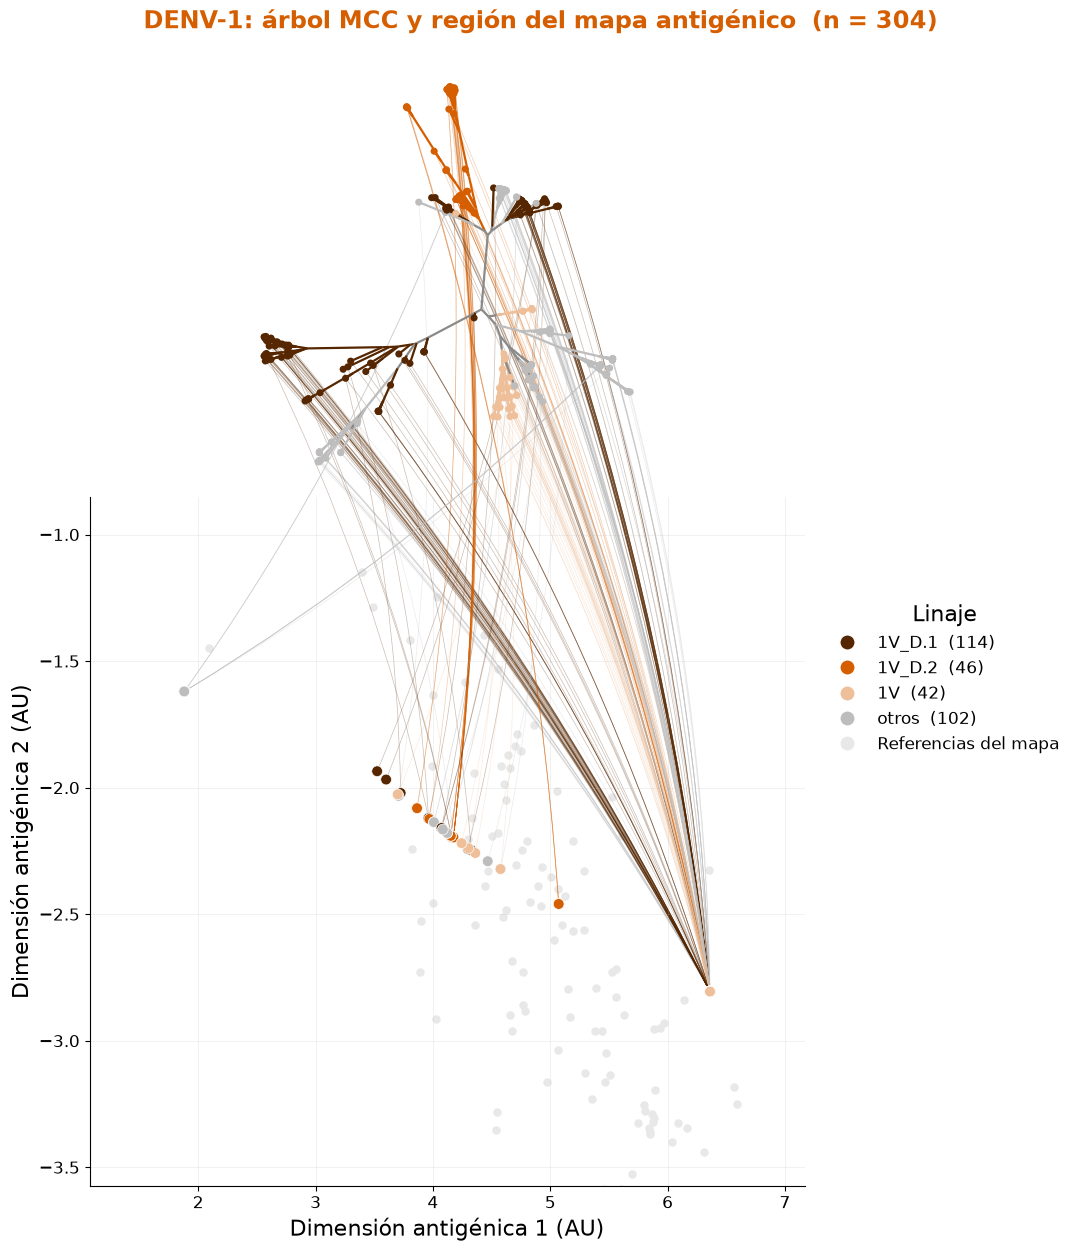

DENV2: 467 puntas con coordenadas | x [-4.0, -1.3] | y [-3.0, -0.2]


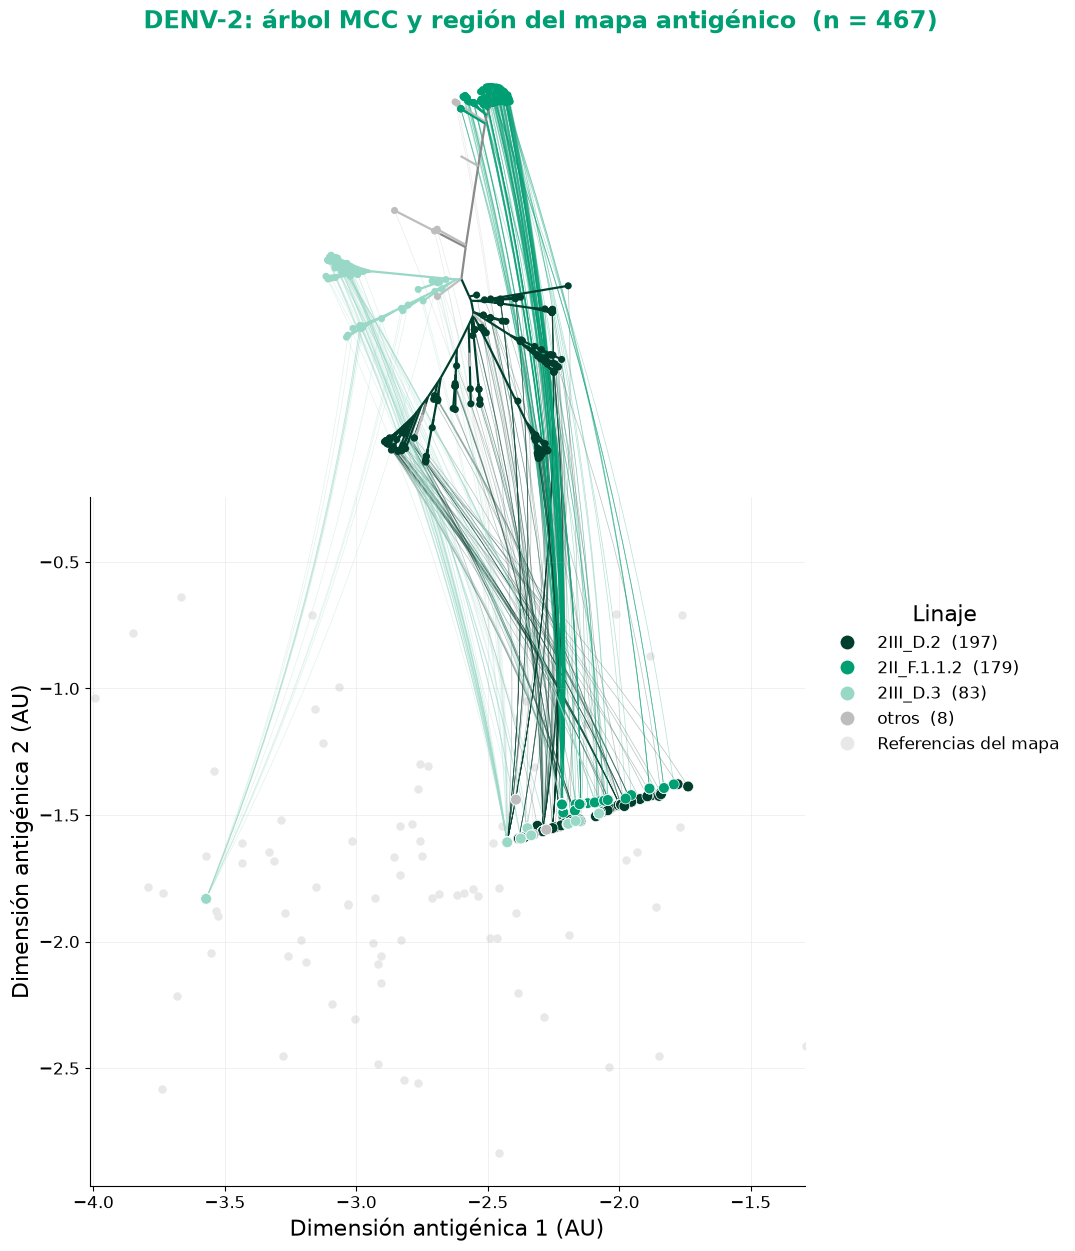

DENV3: 261 puntas con coordenadas | x [-2.3, 0.4] | y [1.6, 4.3]


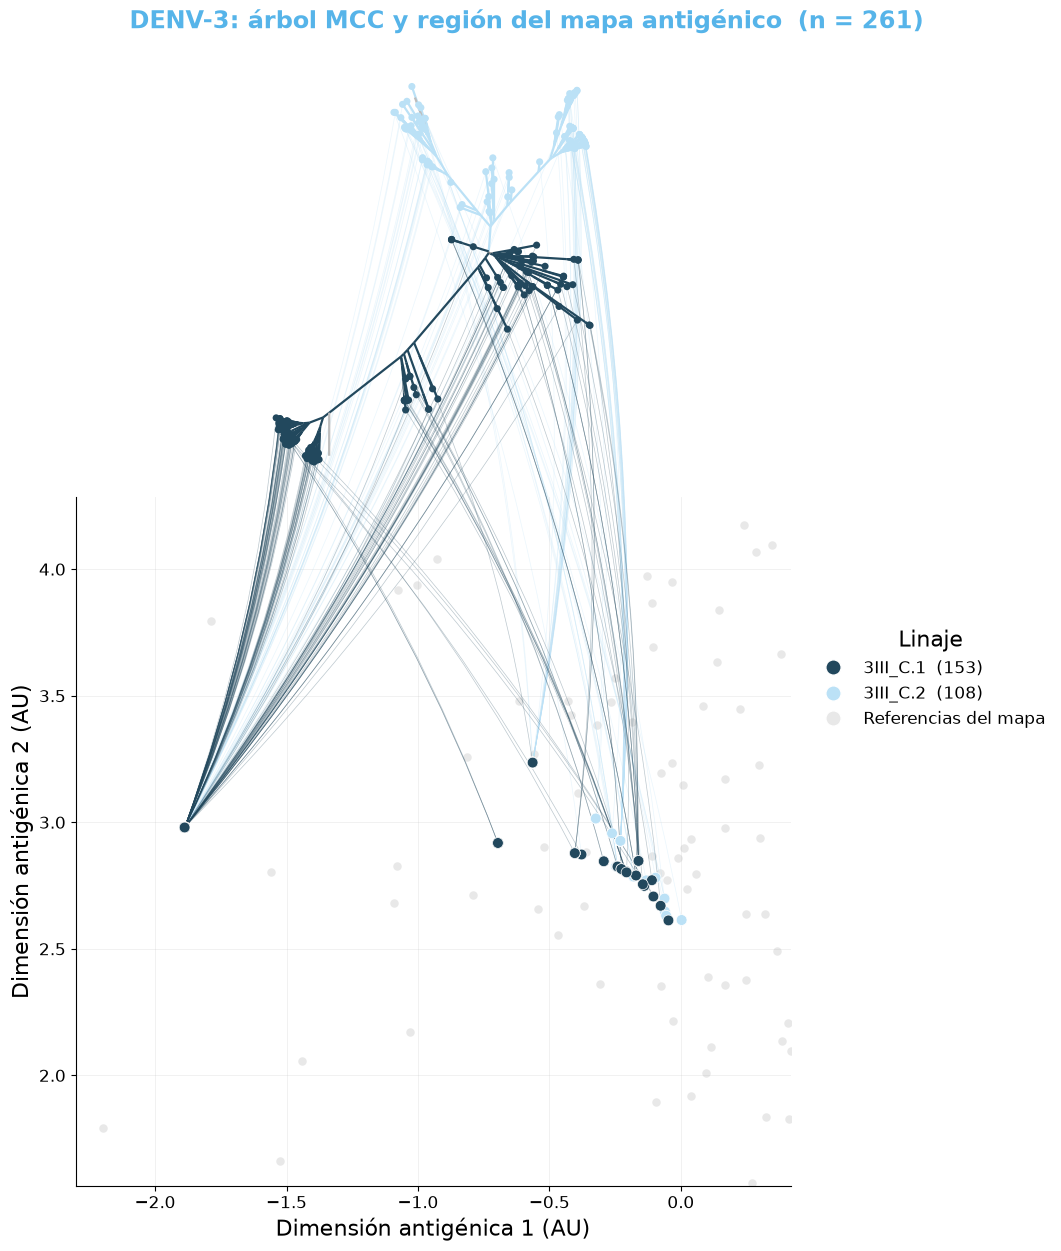

DENV4: 48 puntas con coordenadas | x [-3.8, -1.1] | y [-0.1, 2.6]


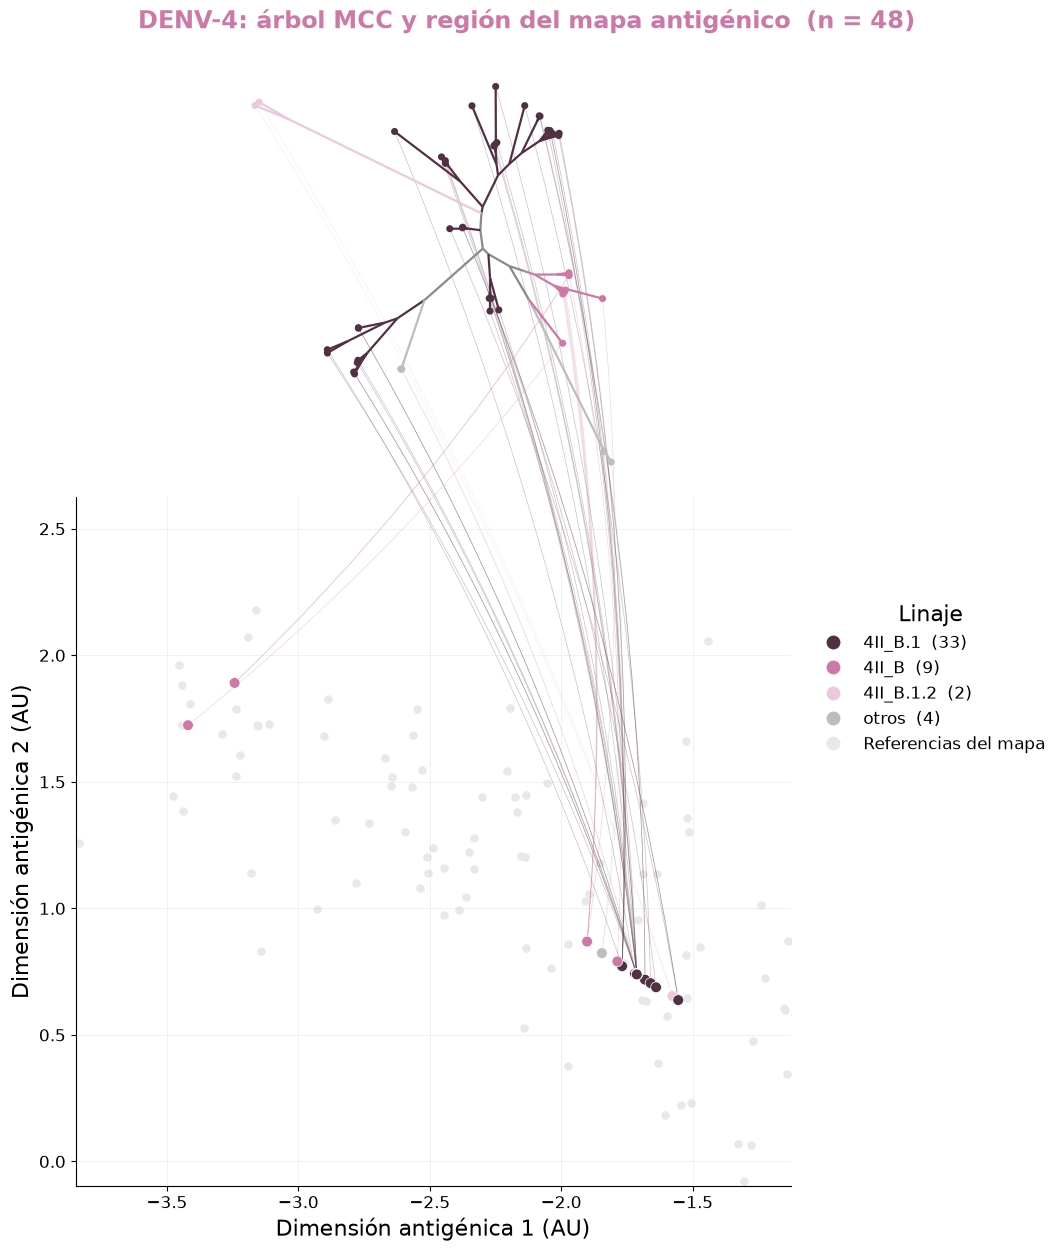

In [22]:
# Respaldo: un panel por serotipo, con el mapa recortado a su región.
# Reusa lineage_shades, unrooted_layout y load_beast_tree de la celda anterior.

SPAN_MIN = 2.0        # amplitud mínima de cada eje, para que no haga zoom absurdo
                      # cuando las proyecciones de un serotipo colapsan en una línea


def plot_tree_map_sero(sero, projected_coordinates, ref_xy=None, connect=True,
                       rotate=0.2, out=None, max_linajes=MAX_LINAJES, pad=0.18):
    base = SERO_COLORS[sero]
    proj = projected_coordinates[sero]

    ll = load_beast_tree(TREE_FILES[sero], DATES_FILES[sero])
    tips = [k for k in ll.Objects if k.branchType == "leaf"]
    con_coord = [k.name for k in tips if k.name in proj.index]
    xy = {t: proj.loc[t, ["X", "Y"]].values.astype(float) for t in con_coord}

    linajes = lineage_series(META_CLEAN_COL, sero).dropna().astype(str)
    grp = {t: linajes.get(t) for t in con_coord}
    conteo = pd.Series([g for g in grp.values() if g]).value_counts()
    top = list(conteo.index[:max_linajes])
    lcol = dict(zip(top, lineage_shades(base, len(top))))
    color_of = lambda n: lcol.get(grp.get(n), GRIS_OTROS)
    n_otros = int(conteo[~conteo.index.isin(top)].sum())

    fig = plt.figure(figsize=(11, 13), facecolor="w")
    gs = gridspec.GridSpec(2, 1, height_ratios=[0.6, 1], hspace=0.03,
                           left=0.09, right=0.74, top=0.92, bottom=0.06)
    ax_map = fig.add_subplot(gs[1])
    ax_tree = fig.add_subplot(gs[0])

    # --- región del mapa que ocupa este serotipo
    pts = np.array([xy[n] for n in con_coord])
    (x0, y0), (x1, y1) = pts.min(axis=0), pts.max(axis=0)
    for lo, hi, set_lim in ((x0, x1, ax_map.set_xlim), (y0, y1, ax_map.set_ylim)):
        span = max(hi - lo, SPAN_MIN)
        c = (lo + hi) / 2
        set_lim(c - span * (0.5 + pad), c + span * (0.5 + pad))

    if ref_xy is not None:
        ax_map.scatter(ref_xy.coord1, ref_xy.coord2, s=26, c="#e8e8e8", zorder=0)

    # --- árbol
    hojas_de = {id(k): ({k.name} if k.branchType == "leaf" else set(k.leaves))
                for k in ll.Objects}

    def c_rama(k):
        if k.branchType == "leaf":
            return color_of(k.name)
        gs_ = {grp.get(h) for h in hojas_de[id(k)] if h in xy}
        return lcol.get(next(iter(gs_)), GRIS_OTROS) if len(gs_) == 1 else "#8A8A8A"

    edges, pos = unrooted_layout(ll, rotate)
    ax_tree.add_collection(LineCollection([[e[2], e[3]] for e in edges],
                                          colors=[c_rama(e[1]) for e in edges],
                                          linewidths=1.6, zorder=10))
    leaf_xy = {k.name: pos[id(k)] for k in tips}
    ax_tree.scatter([leaf_xy[n][0] for n in con_coord],
                    [leaf_xy[n][1] for n in con_coord],
                    c=[color_of(n) for n in con_coord], s=26, zorder=20, linewidths=0)
    ax_tree.autoscale_view()
    ax_tree.set_aspect("equal", adjustable="datalim")
    for sp in ax_tree.spines.values():
        sp.set_visible(False)
    ax_tree.set_xticks([])
    ax_tree.set_yticks([])
    ax_tree.set_facecolor("none")
    ax_tree.set_zorder(4)

    # --- puntos proyectados y conexiones
    ax_map.scatter(pts[:, 0], pts[:, 1], c=[color_of(n) for n in con_coord],
                   edgecolor="white", linewidths=0.5, s=60, zorder=3)
    if connect:
        for n in con_coord:
            ax_map.add_artist(ConnectionPatch(
                xyA=tuple(xy[n]), coordsA=ax_map.transData,
                xyB=tuple(leaf_xy[n]), coordsB=ax_tree.transData,
                color=color_of(n), linewidth=0.5, alpha=0.3,
                connectionstyle="arc3,rad=0.06", zorder=0))

    ax_map.set_xlabel("Dimensión antigénica 1 (AU)", fontsize=16)
    ax_map.set_ylabel("Dimensión antigénica 2 (AU)", fontsize=16)
    ax_map.tick_params(axis="both", labelsize=12)
    for sp in ("right", "top"):
        ax_map.spines[sp].set_visible(False)
    ax_map.grid(alpha=0.2, lw=0.6)

    handles = [Line2D([0], [0], marker="o", color="w", markersize=11,
                      markerfacecolor=lcol[l], label=f"{l}  ({conteo[l]})")
               for l in top]
    if n_otros:
        handles.append(Line2D([0], [0], marker="o", color="w", markersize=11,
                              markerfacecolor=GRIS_OTROS, label=f"otros  ({n_otros})"))
    if ref_xy is not None:
        handles.append(Line2D([0], [0], marker="o", color="w", markersize=11,
                              markerfacecolor="#e8e8e8", label="Referencias del mapa"))
    fig.legend(handles=handles, title="Linaje", loc="center left",
               bbox_to_anchor=(0.75, 0.45), frameon=False,
               fontsize=12, title_fontsize=16)

    fig.suptitle(f"DENV-{sero}: árbol MCC y región del mapa antigénico  (n = {len(con_coord)})",
                 fontsize=17, fontweight="bold", color=base, y=0.965)
    print(f"DENV{sero}: {len(con_coord)} puntas con coordenadas | "
          f"x [{ax_map.get_xlim()[0]:.1f}, {ax_map.get_xlim()[1]:.1f}] | "
          f"y [{ax_map.get_ylim()[0]:.1f}, {ax_map.get_ylim()[1]:.1f}]")
    if out:
        plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()


for sero in [1, 2, 3, 4]:
    plot_tree_map_sero(sero, projected_coordinates,
                       ref_xy=mapa_ag[mapa_ag.type == "AG"],
                       out=f"../figures/arbol_mapa_DENV{sero}.png")


## Matrices de distancia patristicas

In [27]:
import numpy as np
import pandas as pd


def patristic_matrix(ll):
    """Distancias patrísticas entre las puntas de un árbol de baltic.

    d(a,b) = h(a) + h(b) - 2*h(MRCA), con h la suma de longitudes de rama
    desde la raíz. En un árbol temporal de BEAST la unidad son años.

    Se arma de una vez con la matriz de ancestros A (puntas x nodos):
    h = A·L da la altura de cada punta y (A*L)·Aᵀ el tramo de camino que
    comparten los dos, así no hace falta recorrer el árbol por cada par.
    """
    objs = ll.Objects
    pos = {id(o): i for i, o in enumerate(objs)}
    L = np.array([o.length for o in objs], dtype=float)

    tips = [o for o in objs if o.branchType == "leaf"]
    A = np.zeros((len(tips), len(objs)), dtype=float)
    for i, t in enumerate(tips):
        n = t
        while n is not None and id(n) in pos:
            A[i, pos[id(n)]] = 1.0
            n = n.parent

    h = A @ L
    compartido = (A * L) @ A.T
    D = h[:, None] + h[None, :] - 2.0 * compartido
    np.fill_diagonal(D, 0.0)
    D = np.maximum(D, 0.0)          # limpia el -1e-15 del redondeo

    nombres = [t.name for t in tips]
    return pd.DataFrame(D, index=nombres, columns=nombres)


patristic = {}
for sero in [1, 2, 3, 4]:
    ll = load_beast_tree(TREE_FILES[sero], DATES_FILES[sero])
    M = patristic[sero] = patristic_matrix(ll)

    filename = PATRISTIC_FILE.format(sero=sero)
    M.to_csv(filename, index=True)

    triu = M.values[np.triu_indices(len(M), k=1)]
    print(f"DENV{sero}: {M.shape[0]} puntas | mediana {np.median(triu):.2f} años | "
          f"max {triu.max():.2f} años -> {filename}")


DENV1: 308 puntas | mediana 24.55 años | max 47.54 años -> ../output/patristic_MCC_DENV1.csv
DENV2: 475 puntas | mediana 34.29 años | max 52.45 años -> ../output/patristic_MCC_DENV2.csv
DENV3: 264 puntas | mediana 21.34 años | max 41.39 años -> ../output/patristic_MCC_DENV3.csv
DENV4: 48 puntas | mediana 18.78 años | max 42.47 años -> ../output/patristic_MCC_DENV4.csv


DENV1: 308 hojas | 304 con coordenadas proyectadas
   Mantel (spearman): r = 0.081, p = 0.0080 | pares = 46056
DENV2: 475 hojas | 467 con coordenadas proyectadas
   Mantel (spearman): r = 0.285, p = 0.0010 | pares = 108811
DENV3: 264 hojas | 261 con coordenadas proyectadas
   Mantel (spearman): r = 0.153, p = 0.0010 | pares = 33930
DENV4: 48 hojas | 48 con coordenadas proyectadas
   Mantel (spearman): r = 0.106, p = 0.1200 | pares = 1128


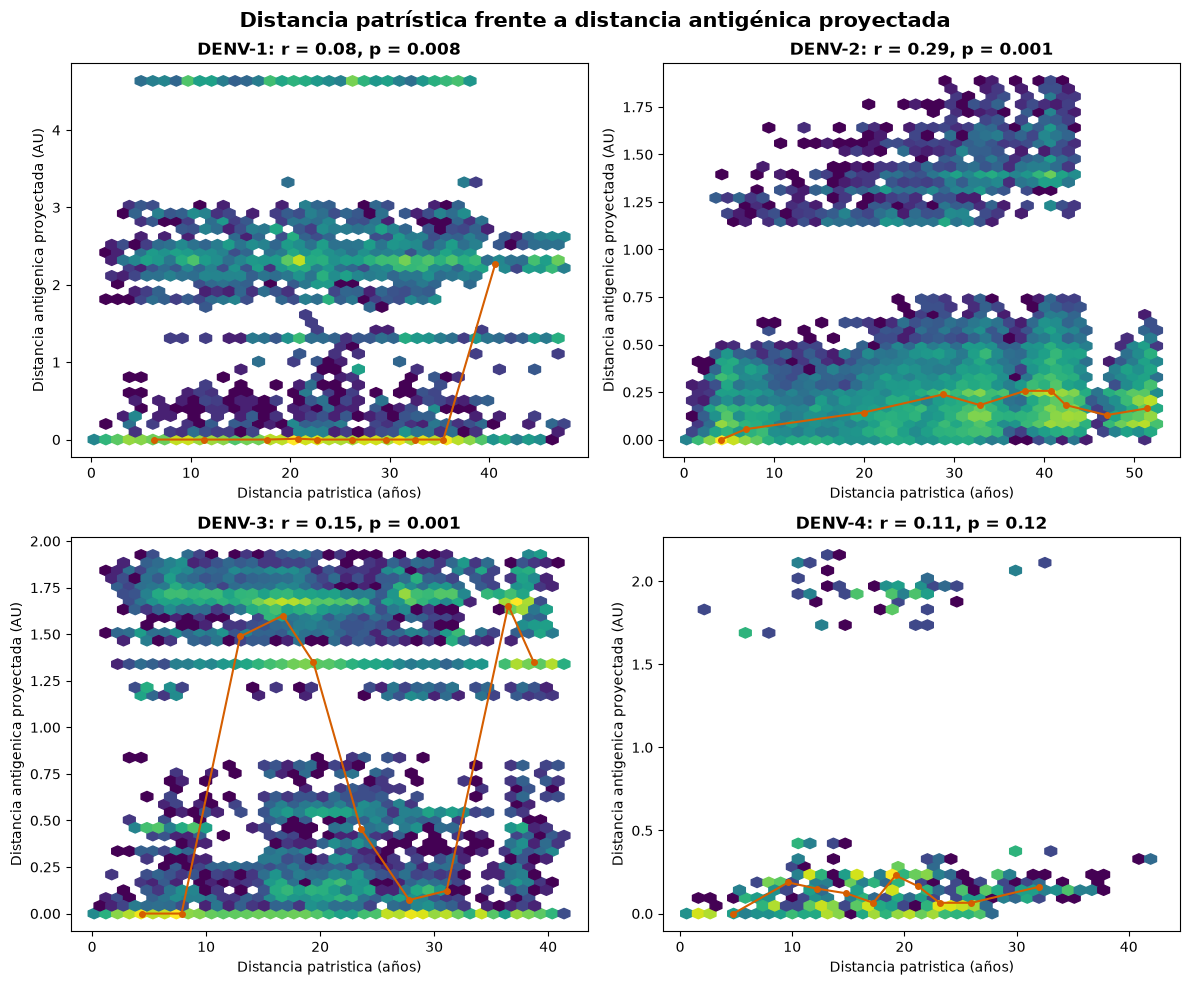

 serotipo  n_puntas  n_pares      r     p   metodo
        1       304    46056 0.0807 0.008 spearman
        2       467   108811 0.2851 0.001 spearman
        3       261    33930 0.1529 0.001 spearman
        4        48     1128 0.1056 0.120 spearman


In [29]:
# ───────────── Prueba de Mantel ─────────────
def mantel(A, B, method="spearman", perms=999, seed=0):
    """Correlacion entre dos matrices de distancias y valor p por permutacion de las etiquetas
    (las distancias por pares no son independientes, asi que un p de Pearson/Spearman seria enganoso).

    Para Spearman se rangea una sola vez la matriz completa: permutar filas y columnas
    a la vez no cambia el multiconjunto de distancias, asi que los rangos se conservan
    y no hace falta volver a rangear en cada permutacion.
    """
    n = A.shape[0]
    iu = np.triu_indices(n, 1)

    if method == "spearman":
        A = _rank_matrix(A)
        B = _rank_matrix(B)
    a = A[iu]
    r_obs = np.corrcoef(a, B[iu])[0, 1]

    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(perms):
        p = rng.permutation(n)
        r = np.corrcoef(a, B[np.ix_(p, p)][iu])[0, 1]
        count += (r >= r_obs - 1e-12)
    return r_obs, (count + 1) / (perms + 1)       # prueba de una cola: asociacion positiva


def _rank_matrix(M):
    """Reemplaza cada distancia por su rango entre todos los pares, conservando la simetria."""
    n = M.shape[0]
    iu = np.triu_indices(n, 1)
    R = np.zeros_like(M, dtype=float)
    R[iu] = rankdata(M[iu])
    return R + R.T


# ───────────── Analisis por serotipo ─────────────
def patristic_vs_antigenic(sero, patristic, projected_coordinates,
                           perms=999, method="spearman", ax=None, out=None):
    """Usa las matrices patristicas ya calculadas y las coordenadas proyectadas."""
    P_df = patristic[sero]
    proj = projected_coordinates[sero]

    comunes = [n for n in P_df.index if n in proj.index]
    print(f"DENV{sero}: {P_df.shape[0]} hojas | {len(comunes)} con coordenadas proyectadas")
    if len(comunes) < 3:
        raise ValueError("Muy pocas hojas emparejadas: revisa los nombres del MCC")

    P = P_df.loc[comunes, comunes].to_numpy(dtype=float)
    xy = proj.loc[comunes, ["X", "Y"]].to_numpy(dtype=float)
    A = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1))   # distancia antigenica proyectada

    r, p = mantel(P, A, method=method, perms=perms)
    iu = np.triu_indices(len(comunes), 1)
    print(f"   Mantel ({method}): r = {r:.3f}, p = {p:.4f} | pares = {len(iu[0])}")

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    ax.hexbin(P[iu], A[iu], gridsize=40, bins="log", cmap="viridis", mincnt=1)
    # mediana de la distancia antigenica por intervalos de distancia patristica
    qs = np.quantile(P[iu], np.linspace(0, 1, 11))
    cen, med = [], []
    for lo, hi in zip(qs[:-1], qs[1:]):
        m = (P[iu] >= lo) & (P[iu] <= hi)
        if m.any():
            cen.append(P[iu][m].mean())
            med.append(np.median(A[iu][m]))
    ax.plot(cen, med, "-o", color="#D55E00", ms=4, lw=1.5)   # mediana por decil
    ax.set_xlabel("Distancia patristica (años)")
    ax.set_ylabel("Distancia antigenica proyectada (AU)")
    ax.set_title(f"DENV-{sero}: r = {r:.2f}, p = {p:.3g}", fontweight="bold")
    if out:
        plt.savefig(out, dpi=300, bbox_inches="tight")
    return dict(serotipo=sero, n_puntas=len(comunes), n_pares=len(iu[0]),
                r=r, p=p, metodo=method)


# ───────────── Uso ─────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
res = [patristic_vs_antigenic(s, patristic, projected_coordinates,
                              ax=axes.flatten()[s - 1]) for s in [1, 2, 3, 4]]
fig.suptitle("Distancia patrística frente a distancia antigénica proyectada",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("../figures/patristica_vs_antigenica.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print(pd.DataFrame(res).round(4).to_string(index=False))


## Analisis Re

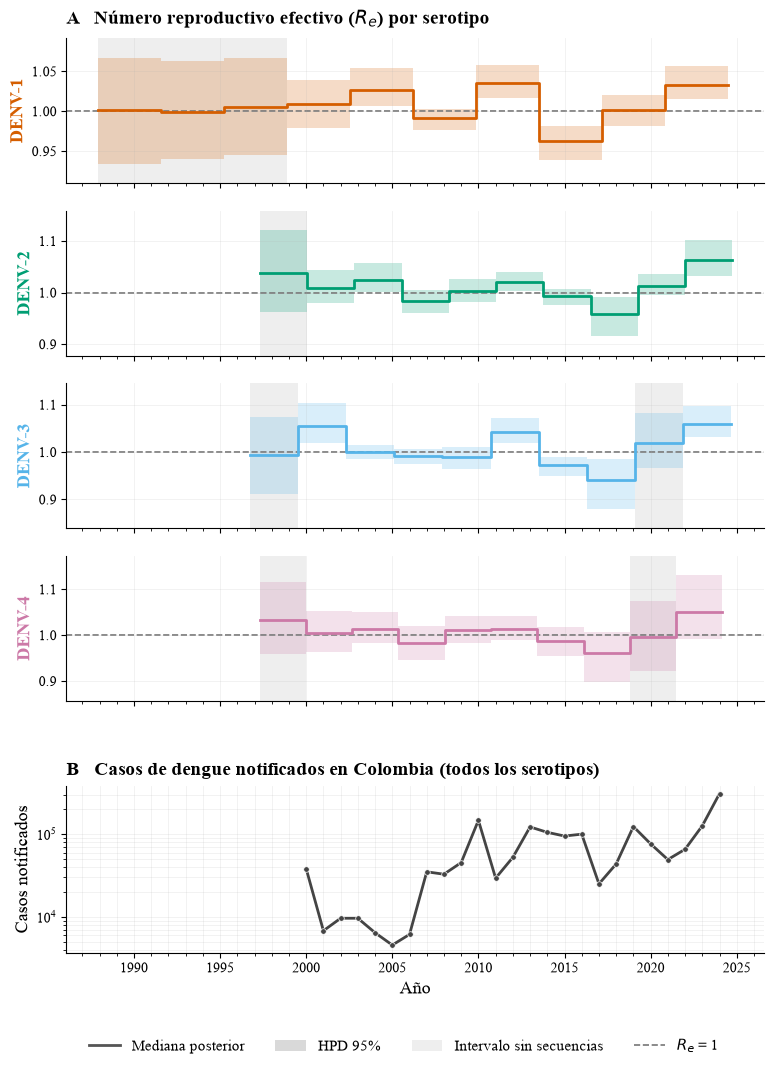

 serotipo  intervalo      ini      fin   n  mediana    lo    hi  ancho
        1          1 1987.917 1991.573   0    1.001 0.934 1.067  0.133
        1          2 1991.573 1995.230   0    1.000 0.940 1.064  0.124
        1          3 1995.230 1998.886   0    1.006 0.945 1.066  0.121
        1          4 1998.886 2002.542   5    1.009 0.979 1.039  0.060
        1          5 2002.542 2006.198   6    1.027 1.007 1.055  0.048
        1          6 2006.198 2009.855  61    0.991 0.977 1.003  0.027
        1          7 2009.855 2013.511 111    1.035 1.017 1.058  0.041
        1          8 2013.511 2017.167  33    0.963 0.939 0.981  0.042
        1          9 2017.167 2020.823   8    1.001 0.981 1.020  0.039
        1         10 2020.823 2024.480  83    1.033 1.015 1.057  0.042
        2          1 1997.318 2000.060   0    1.038 0.962 1.121  0.159
        2          2 2000.060 2002.802   9    1.009 0.979 1.043  0.064
        2          3 2002.802 2005.544  26    1.025 1.001 1.057  0.056
      

In [35]:
BDSKY_LOG = "../resources/BEAST/DENV{sero}_BDSKY.log"
CASOS_FILE = r"D:\EQUIPO\Documents HDD\Tesis\dengue\dengue_yearly_counts.csv"
BURNIN = 0.10            # mismo 10% que usa bdsky_plot.R


def hpd(x, cred=0.95):
    """Intervalo de densidad posterior mas alta: el mas corto que contiene cred."""
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    k = int(np.floor(cred * n))
    i = int(np.argmin(x[k:] - x[:n - k]))
    return x[i], x[i + k]


def re_skyline(sero):
    """Mediana e HPD 95% de Re por intervalo del skyline, ubicados en el tiempo.

    En BDSKY el indice 1 es el intervalo mas antiguo y el ultimo el mas reciente
    (misma convencion que bdsky_plot.R de D. Kuhnert). Los intervalos son
    equiespaciados entre el origen y la muestra mas reciente. Se cuenta ademas
    cuantas secuencias caen en cada intervalo: donde no hay, el HPD se dispara.
    """
    log = pd.read_csv(BDSKY_LOG.format(sero=sero), sep="\t", comment="#")
    log = log.iloc[int(len(log) * BURNIN):]
    cols = sorted([c for c in log.columns if c.startswith("reproductiveNumber")],
                  key=lambda c: int(c.split(".")[-1]))

    fechas = np.array([float(l.split("\t")[1])
                       for l in open(DATES_FILES[sero]) if l.strip()])
    reciente = fechas.max()
    width = log["origin_BDSKY_Serial"].median()
    paso = width / len(cols)

    filas = []
    for i, c in enumerate(cols, start=1):
        lo, hi = hpd(log[c].to_numpy())
        ini = reciente - width + (i - 1) * paso
        filas.append(dict(serotipo=sero, intervalo=i, ini=ini, fin=ini + paso,
                          centro=ini + paso / 2, mediana=log[c].median(),
                          lo=lo, hi=hi,
                          n=int(((fechas >= ini) & (fechas < ini + paso)).sum())))
    return pd.DataFrame(filas)


# ---------------------------------------------------------------- figura
plt.rcParams["font.family"] = "Times New Roman"
fig, axes = plt.subplots(5, 1, figsize=(9, 11.5), sharex=True,
                         gridspec_kw=dict(height_ratios=[1, 1, 1, 1, 1.35], hspace=0.18))
# el panel de casos necesita aire para su titulo
p = axes[4].get_position()
axes[4].set_position([p.x0, p.y0 - 0.025, p.width, p.height - 0.025])

skylines = {}
for ax, sero in zip(axes[:4], [1, 2, 3, 4]):
    t = skylines[sero] = re_skyline(sero)
    c = SERO_COLORS[sero]

    # el skyline es constante a trozos: escalon, no curva suave
    bordes = list(t.ini) + [t.fin.iloc[-1]]
    paso_v = lambda v: list(v) + [v.iloc[-1]]
    ax.fill_between(bordes, paso_v(t.lo), paso_v(t.hi), step="post",
                    color=c, alpha=0.22, lw=0)
    ax.step(bordes, paso_v(t.mediana), where="post", color=c, lw=2, zorder=3)

    # intervalos sin una sola secuencia: ahi el HPD solo refleja el prior
    for _, r in t[t.n == 0].iterrows():
        ax.axvspan(r.ini, r.fin, color="#999999", alpha=0.16, lw=0, zorder=0)

    ax.axhline(1.0, color="#777777", lw=1.2, ls="--", zorder=1)
    ax.set_ylabel(f"DENV-{sero}", fontsize=13, fontweight="bold", color=c)
    ax.grid(alpha=0.18, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.18)

# Casos anuales notificados en Colombia, sin desagregar por serotipo
casos = pd.read_csv(CASOS_FILE).sort_values("year")
axB = axes[4]
axB.plot(casos.year, casos["count"], "-o", color="#444444", lw=2, ms=4,
         markeredgecolor="white", markeredgewidth=0.5)
axB.set_yscale("log")
axB.set_ylabel("Casos notificados", fontsize=13)
axB.set_xlabel("Año", fontsize=13)
axB.grid(alpha=0.18, lw=0.6, which="both")
axB.spines[["top", "right"]].set_visible(False)
axB.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(5))
axB.xaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(1))

axes[0].set_title("A   Número reproductivo efectivo ($R_e$) por serotipo",
                  loc="left", fontsize=14, fontweight="bold", pad=10)
axB.set_title("B   Casos de dengue notificados en Colombia (todos los serotipos)",
              loc="left", fontsize=14, fontweight="bold", pad=8)

h = [Line2D([], [], color="#555555", lw=2, label="Mediana posterior"),
     Patch(facecolor="#555555", alpha=0.22, label="HPD 95%"),
     Patch(facecolor="#999999", alpha=0.16, label="Intervalo sin secuencias"),
     Line2D([], [], color="#777777", lw=1.2, ls="--", label="$R_e$ = 1")]
fig.legend(handles=h, loc="lower center", ncol=4, frameon=False, fontsize=11,
           bbox_to_anchor=(0.5, -0.015))

fig.savefig("../figures/bdsky_Re_serotipos.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

tabla_re = pd.concat(skylines.values())
tabla_re.to_csv("../output/bdsky_Re_intervalos.csv", index=False)
print(tabla_re.assign(ancho=lambda d: d.hi - d.lo).round(3)
      [["serotipo", "intervalo", "ini", "fin", "n", "mediana", "lo", "hi", "ancho"]]
      .to_string(index=False))
